In [30]:
exposure_1 = 2026071400700
exposure_2 = 2026102600004
repo_path = "/repo/embargo,/repo/main"
instrument = "LSSTCam"
collection = "LSSTCam/runs/nightlyValidation"
statistic = "STDEV"
level_statistic = "MEDIAN"
residual = False
max_workers = 4
frac_limit = 0

In [31]:
import re
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
import lsst.geom
from lsst.afw.cameraGeom import FOCAL_PLANE, PIXELS
from lsst.daf.butler import Butler, MissingCollectionError
from lsst.pipe.base import Instrument

Overscan statistics are computed by `IsrTaskLSST` and written to the header of `post_isr_image`
(keys `LSST ISR OVERSCAN [RESIDUAL] SERIAL {STDEV|MEAN|MEDIAN} Cxx`). The serial overscan
`statistic` (noise) and `level_statistic` (level, MEAN or MEDIAN) are compared side by side. Only the `metadata`
component is read, not the pixels.

`repo_path` is a comma-separated list searched in order, since older data are moved from
`/repo/embargo` to `/repo/main`. Each exposure is taken from the first repository that has it.

In [32]:
exposure_1 = int(exposure_1)
exposure_2 = int(exposure_2)
max_workers = int(max_workers)
frac_limit = float(frac_limit)
residual = str(residual).lower() in ("true", "1", "yes")
stats = [statistic.upper(), level_statistic.upper()]

repos = [r.strip() for r in repo_path.split(",") if r.strip()]
butlers = {}

prefix = "LSST ISR OVERSCAN " + ("RESIDUAL " if residual else "")
key_re = re.compile(rf"^{prefix}SERIAL ({'|'.join(stats)}) (C\d\d)$")


def get_butler(repo):
    if repo not in butlers:
        butlers[repo] = Butler(repo, collections=[collection])
    return butlers[repo]


def find_refs(exposure):
    for repo in repos:
        butler = get_butler(repo)
        try:
            with butler.query() as q:
                refs = list(
                    q.datasets("post_isr_image").where(
                        f"instrument='{instrument}' AND exposure={exposure}"
                    ).limit(1000)
                )
        except MissingCollectionError:
            continue
        if refs:
            return repo, butler, refs
    raise LookupError(f"No post_isr_image for exposure {exposure} in {collection} of {repos}")


def read_overscan(butler, ref):
    md = butler.get(ref.makeComponentRef("metadata"))
    rows = []
    for k in md.names():
        m = key_re.match(k)
        if m:
            rows.append(dict(detector=ref.dataId["detector"], amp=m.group(2),
                             stat=m.group(1), value=md[k]))
    return rows, md.get("LSST ISR OVERSCAN SERIAL UNITS")


def load_exposure(exposure):
    repo, butler, refs = find_refs(exposure)
    rows, units = [], None
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        for r, u in pool.map(lambda ref: read_overscan(butler, ref), refs):
            rows += r
            units = units or u
    rec = butler.registry.expandDataId(refs[0].dataId).records["exposure"]
    print(f"{rec.id}: {rec.observation_type:8s} {rec.exposure_time:6.1f}s  filter={rec.physical_filter}  "
          f"{rec.timespan.begin.isot}  ({repo}, {refs[0].run})")
    return pd.DataFrame(rows), units, butler

In [33]:
df1, units, butler1 = load_exposure(exposure_1)
df2, _, butler2 = load_exposure(exposure_2)

camera = Instrument.from_string(instrument, butler1.registry).getCamera()
detnames = {det.getId(): det.getName() for det in camera}

df = df1.merge(df2, on=["detector", "amp", "stat"], suffixes=("_1", "_2"))
df["detname"] = df["detector"].map(detnames)
df["ratio"] = df["value_2"] / df["value_1"]
df["frac"] = (df["value_2"] - df["value_1"]) / df["value_1"]

print(f"{df.detector.nunique()} detectors, {len(df)} (amp, statistic) pairs matched")

2026071400700: dark       30.0s  filter=none  2026-07-15T10:58:26.742825  (/repo/main, LSSTCam/runs/nightlyValidation/68)
2026102600004: dark        5.0s  filter=i_39  2026-10-26T22:46:23.211605  (/repo/embargo, LSSTCam/runs/nightlyValidation/69)
197 detectors, 6172 (amp, statistic) pairs matched


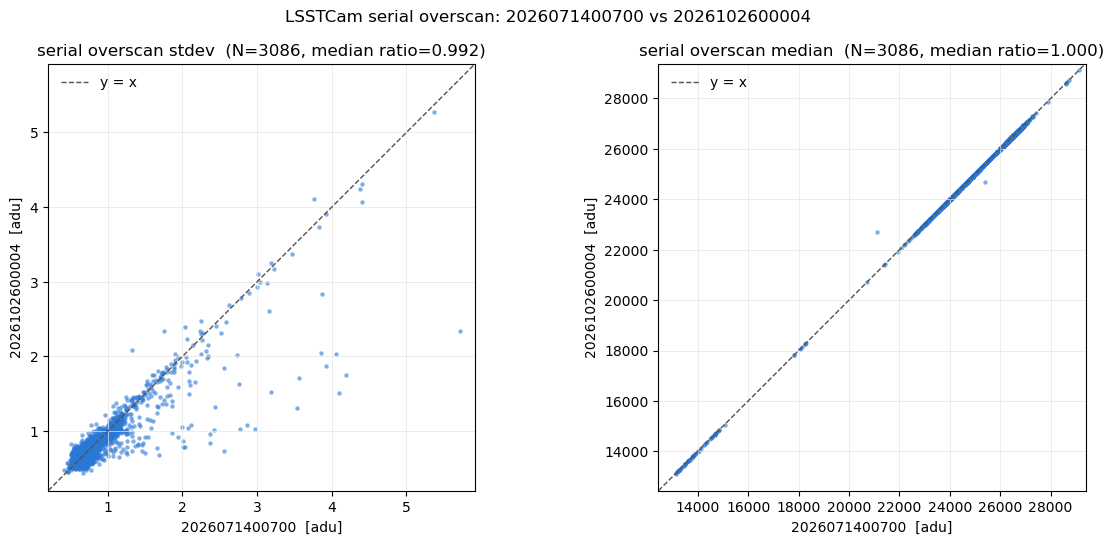

In [34]:
label = f"serial {'residual ' if residual else ''}overscan"
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, stat in zip(axes, stats):
    d = df[df["stat"] == stat]
    if d.empty:
        ax.set_visible(False)
        continue
    ax.scatter(d["value_1"], d["value_2"], s=10, color="#2a78d6", alpha=0.6, linewidths=0)
    lo = np.nanpercentile(np.r_[d["value_1"], d["value_2"]], 0.1)
    hi = np.nanpercentile(np.r_[d["value_1"], d["value_2"]], 99.9)
    pad = 0.05 * (hi - lo)
    lim = (lo - pad, hi + pad)
    ax.plot(lim, lim, color="#52514e", lw=1, ls="--", label="y = x")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect("equal")
    u = units or ""
    ax.set_xlabel(f"{exposure_1}  [{u}]")
    ax.set_ylabel(f"{exposure_2}  [{u}]")
    ax.set_title(f"{label} {stat.lower()}  (N={len(d)}, median ratio={d['ratio'].median():.3f})")
    ax.grid(color="#e5e4e0", lw=0.5)
    ax.legend(loc="upper left", frameon=False)
fig.suptitle(f"{instrument} {label}: {exposure_1} vs {exposure_2}")
fig.tight_layout()
plt.show()

Fractional difference `(exposure_2 - exposure_1) / exposure_1` per amplifier on the focal plane,
laid out as in Figure 1 of [CTN-001](https://ctn-001.lsst.io) (focal plane coordinates, viewed through the lenses).
Gray hatched segments have no data in one of the exposures. `frac_limit` sets the color range (±);
0 picks the 98th percentile of |difference| for each panel.

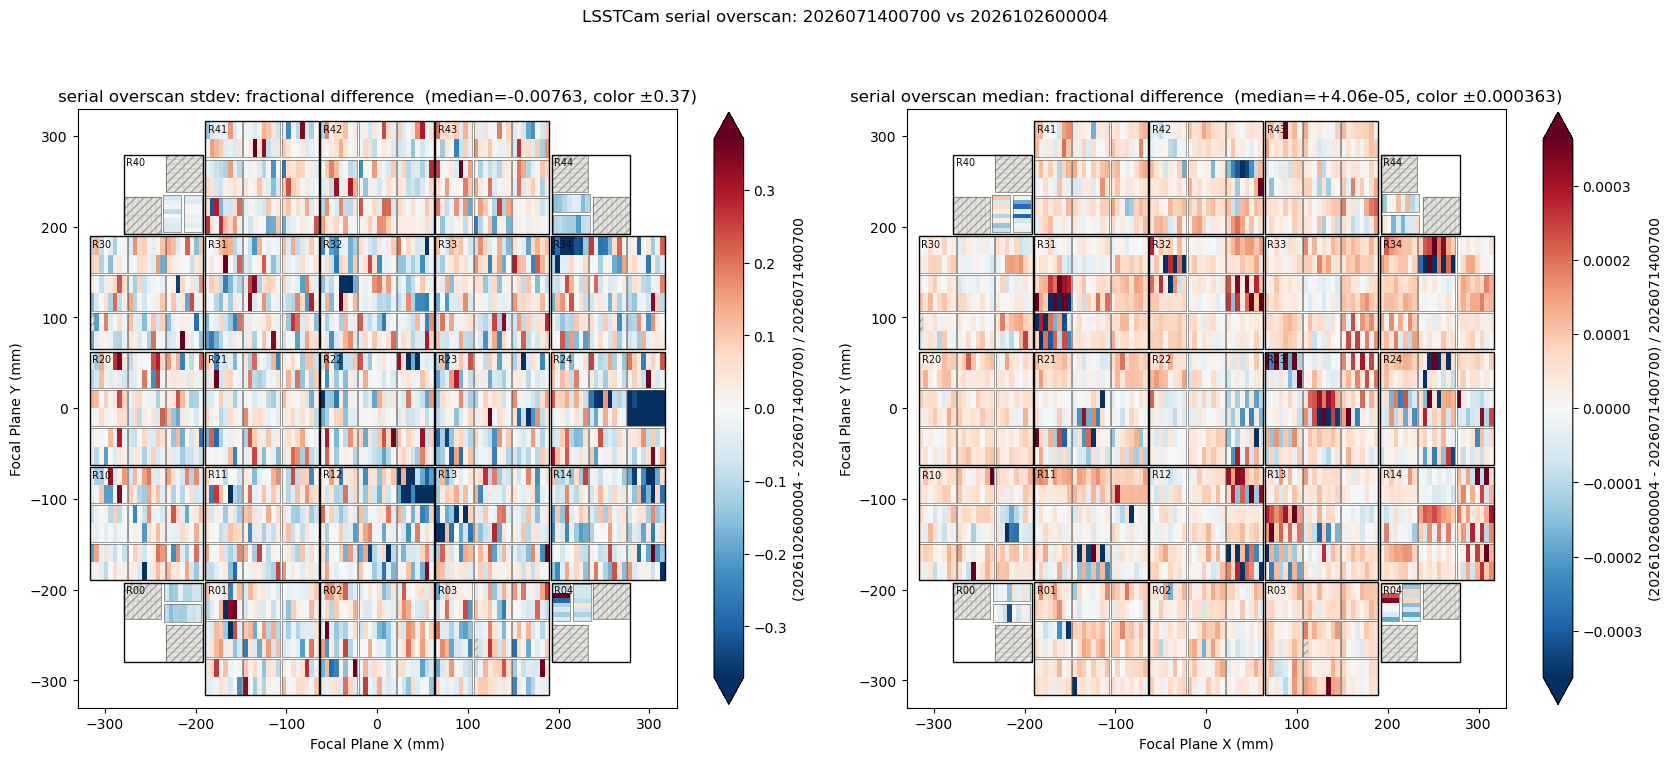

In [35]:
def amp_polygons(det):
    """Corners of each amplifier's data section in focal plane coordinates (mm)."""
    to_fp = det.getTransform(PIXELS, FOCAL_PLANE)
    polys = {}
    for amp in det:
        bb = amp.getBBox()
        corners = [(bb.getMinX() - 0.5, bb.getMinY() - 0.5), (bb.getMaxX() + 0.5, bb.getMinY() - 0.5),
                   (bb.getMaxX() + 0.5, bb.getMaxY() + 0.5), (bb.getMinX() - 0.5, bb.getMaxY() + 0.5)]
        polys[amp.getName()] = [(p.getX(), p.getY()) for p in
                                (to_fp.applyForward(lsst.geom.Point2D(x, y)) for x, y in corners)]
    return polys


def det_outline(det):
    return [(p.getX(), p.getY()) for p in det.getCorners(FOCAL_PLANE)]


geometry = {det.getId(): amp_polygons(det) for det in camera}
outlines = [det_outline(det) for det in camera]

rafts = {}
for det in camera:
    rafts.setdefault(det.getName().split("_")[0], []).extend(det_outline(det))

fig, axes = plt.subplots(1, 2, figsize=(17, 8))
for ax, stat in zip(axes, stats):
    d = df[df["stat"] == stat].set_index(["detector", "amp"])["frac"]
    lim = frac_limit if frac_limit > 0 else np.nanpercentile(np.abs(d), 98)
    have, vals, missing = [], [], []
    for det_id, polys in geometry.items():
        for amp, poly in polys.items():
            v = d.get((det_id, amp), np.nan)
            if np.isfinite(v):
                have.append(poly)
                vals.append(v)
            else:
                missing.append(poly)
    pc = PolyCollection(have, array=np.array(vals), cmap="RdBu_r", clim=(-lim, lim),
                        edgecolors="none")
    ax.add_collection(pc)
    ax.add_collection(PolyCollection(missing, facecolors="#e5e4e0", edgecolors="#a3a29c",
                                     hatch="////", linewidths=0.2))
    ax.add_collection(PolyCollection(outlines, facecolors="none", edgecolors="#52514e", linewidths=0.4))
    for raft, pts in rafts.items():
        pts = np.array(pts)
        x0, y0 = pts.min(axis=0)
        x1, y1 = pts.max(axis=0)
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="#0b0b0b", lw=1.0))
        ax.text(x0 + 3, y1 - 3, raft, ha="left", va="top", fontsize=7, color="#0b0b0b")
    cb = fig.colorbar(pc, ax=ax, shrink=0.8, extend="both")
    cb.set_label(f"({exposure_2} - {exposure_1}) / {exposure_1}")
    ax.set_xlim(-330, 330)
    ax.set_ylim(-330, 330)
    ax.set_aspect("equal")
    ax.set_xlabel("Focal Plane X (mm)")
    ax.set_ylabel("Focal Plane Y (mm)")
    ax.set_title(f"{label} {stat.lower()}: fractional difference  "
                 f"(median={np.nanmedian(d):+.3g}, color ±{lim:.3g})")
fig.suptitle(f"{instrument} {label}: {exposure_1} vs {exposure_2}")
fig.tight_layout()
plt.show()

Amplifiers deviating most from the median ratio (per statistic).

In [36]:
pd.set_option("display.width", 200)
for stat in stats:
    d = df[df["stat"] == stat].copy()
    if d.empty:
        continue
    d["dev"] = np.abs(np.log(d["ratio"] / d["ratio"].median()))
    print(f"***** SERIAL {stat} *****")
    print(d.sort_values("dev", ascending=False)
           .head(15)[["detname", "detector", "amp", "value_1", "value_2", "ratio"]]
           .to_string(index=False, float_format="%.3f"))
    print()

***** SERIAL STDEV *****
detname  detector amp  value_1  value_2  ratio
R10_S01        28 C03   37.189    1.023  0.028
R41_S21       169 C02    3.038   12.180  4.009
R12_S22        53 C13    2.552    0.738  0.289
R24_S12       113 C02    2.969    1.030  0.347
R24_S12       113 C15    2.367    0.835  0.353
R22_S22        98 C14    4.095    1.516  0.370
R24_S12       113 C07    2.766    1.025  0.371
R24_S12       113 C05    3.531    1.310  0.371
R24_S12       113 C10    2.869    1.082  0.377
R24_S12       113 C06    2.038    0.790  0.388
R12_S22        53 C07    2.002    0.788  0.394
R24_S12       113 C13    1.685    0.681  0.404
R12_S22        53 C10    2.368    0.963  0.407
R32_S10       138 C16    5.723    2.346  0.410
R23_S12       104 C03    7.143    2.952  0.413

***** SERIAL MEDIAN *****
detname  detector amp   value_1   value_2  ratio
R10_S01        28 C03 21098.291 22701.739  1.076
R01_S01         1 C00 25385.667 24686.714  0.972
R23_S20       105 C16 26881.232 26913.697  1.001
